# Preparação dos parâmetros para RandomForestClassifier

## Descrição

Esse notebook visa uma análise superficial dos dados, seguido de um GridSearch para buscar parâmetros adequados para o RandomForestClassifier que será usado em um dashboard.

## Importação de bibliotecas

In [3]:
import pandas as pd
from sklearn import datasets
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV,train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import json


## Importação de funções criadas para esse notebook

Funções:

1. plot_scatter_graph -> função criada para padronizar e acelerar a geração de gráficos de pontos. 

In [4]:
from tools import plot_scatter_graph

## Preparação do DataFrame

Usado para exploração inicial dos dados

In [5]:
iris = datasets.load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df["Espécie"] = iris.target_names[iris.target]
df["Espécie"] = "Iris " + df["Espécie"]

## EDA

In [6]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Espécie
0,5.1,3.5,1.4,0.2,Iris setosa
1,4.9,3.0,1.4,0.2,Iris setosa
2,4.7,3.2,1.3,0.2,Iris setosa
3,4.6,3.1,1.5,0.2,Iris setosa
4,5.0,3.6,1.4,0.2,Iris setosa


In [7]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


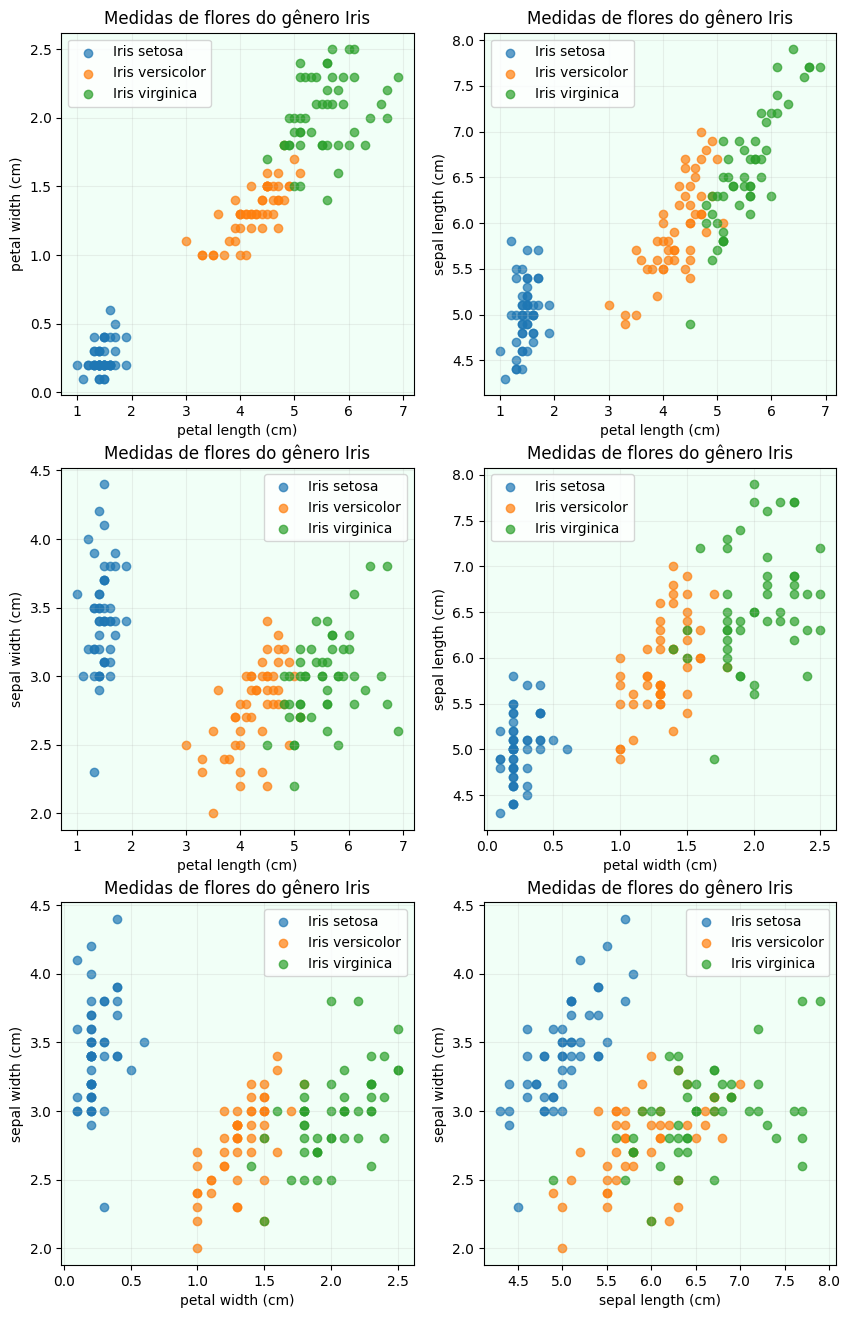

In [8]:
fig, axs = plt.subplots(3, 2, figsize=(10,16))
plot_scatter_graph(axs[0,0], df, "petal length (cm)", "petal width (cm)")
plot_scatter_graph(axs[0,1], df, "petal length (cm)", "sepal length (cm)")
plot_scatter_graph(axs[1,0], df, "petal length (cm)", "sepal width (cm)")

plot_scatter_graph(axs[1,1], df, "petal width (cm)", "sepal length (cm)")
plot_scatter_graph(axs[2,0], df, "petal width (cm)", "sepal width (cm)")

plot_scatter_graph(axs[2,1], df, "sepal length (cm)", "sepal width (cm)")


Text(0.5, 0, '')

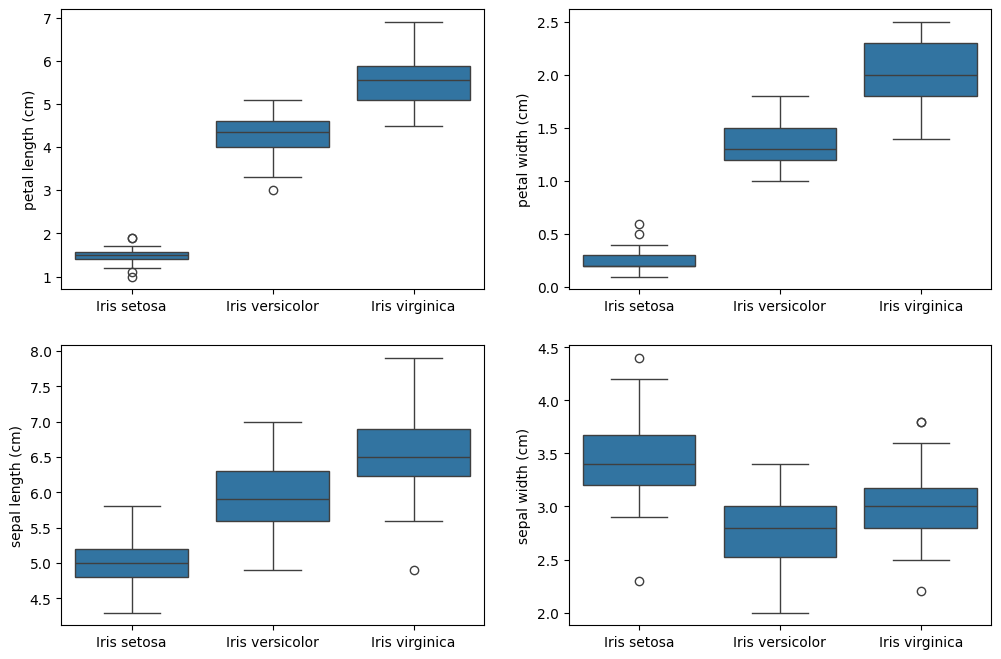

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(12,8))
sns.boxplot(ax=axs[0,0], data=df, x='Espécie', y='petal length (cm)')
axs[0,0].set_xlabel('')

sns.boxplot(ax=axs[0,1], data=df, x='Espécie', y='petal width (cm)')
axs[0,1].set_xlabel('')

sns.boxplot(ax=axs[1,0], data=df, x='Espécie', y='sepal length (cm)')
axs[1,0].set_xlabel('')

sns.boxplot(ax=axs[1,1], data=df, x='Espécie', y='sepal width (cm)')
axs[1,1].set_xlabel('')

# Machine Learning

## Data Split

Separação dos dados em dados de treino, de teste, e isolamento da variável alvo

In [10]:
X = iris.data
Y = iris.target
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

## Parâmetros do Modelo

Foram selecionados os seguintes parâmetros:

1. n_estimators -> buscar o número de árvores adequado para o modelo
2. max_features -> número de features quepodem ser consideradas em cada divisão de nós das árvores
3. max_depth -> quantas divisões sucessivas a árvore pode realizar
4. min_samples_leaf -> número mínimo de observações em cada folha
5. criterion -> critério matemático utilizado

A variável cv define o número de partições que serão utilizadas na validação cruzada

In [11]:
param_grid = { 
    'n_estimators': [100, 200,300, 500], #quantidade de árvores é suficiente?
    'max_features': [ 'sqrt', 'log2'], # diversidade entre árvores
    'max_depth' : [4,5,6,7,8, None], # profundidade.
    'min_samples_leaf': [1,2,4,8],
    'criterion' :['gini', 'entropy'] #critérios de divisão
}

cv = 10

## Ajustando o modelo

Nessa parte, um RandomForestClassifier é gerado e utilizado em um GridSearch com os parâmetros e cv definidos acima.

In [12]:
rf = RandomForestClassifier()
rf_cv = GridSearchCV(rf, param_grid, cv=cv)
rf_cv.fit(X_train, Y_train)

,estimator,RandomForestClassifier()
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [4, 5, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], ...}"
,scoring,None
,n_jobs,None
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


## Resultados do modelo

Aqui temos o score do melhor modelo em relação ao conjunto de testes (não utilizado no treinamento), seguido por um mapa de calor apresentando o resultado desse teste

In [13]:
print("Score: ", rf_cv.score(X_test, Y_test))

Score:  0.9666666666666667


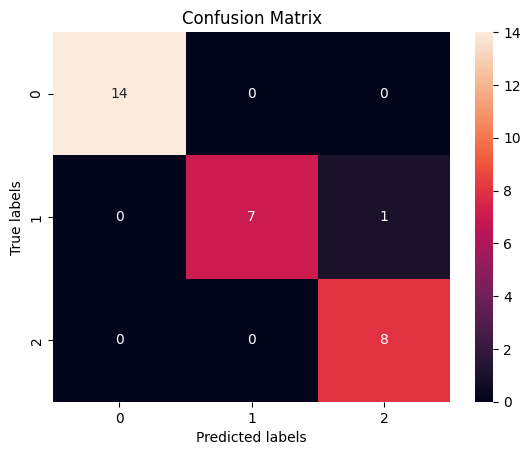

In [14]:
yhat = rf_cv.predict(X_test)


cm = confusion_matrix(Y_test, yhat)
ax= plt.subplot()
sns.heatmap(cm, annot=True, ax = ax); #annot=True to annotate cells
ax.set_xlabel('Predicted labels')
ax.set_ylabel('True labels')
ax.set_title('Confusion Matrix')

plt.show() 

In [15]:
pd.DataFrame(rf_cv.cv_results_)[['mean_fit_time', 'mean_test_score', 'rank_test_score']].sort_values('rank_test_score').head()

,mean_fit_time,mean_test_score,rank_test_score
44,0.124327,0.975000,1
28,0.130140,0.966667,2
324,0.138165,0.966667,2
359,0.989760,0.966667,2
310,0.375518,0.966667,2


## Salvando parametros do modelo

Aqui os parâmetros são exportados como um json, para ser utilizado posteriormente sem a necessidade de usar o notebook.
Esses parâmetros serão utilizados no treinamento direto do modelo, sem a necessidade do GridSearch que já foi realizado aqui

In [16]:
melhores_parametros = rf_cv.best_params_

with open("../model/model_params.json", "w") as f:
    json.dump(melhores_parametros, f, indent=4)